Step 1 — Import libraries and upload dataset

In [2]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

# Upload CSV file
uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)
df.head()

Saving Unemployment in India.csv to Unemployment in India (1).csv
Dataset loaded successfully!
Dataset Shape: (768, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


Step 2 — Data inspection

In [3]:
# Display first 5 rows
print("First 5 rows:")
display(df.head())

# Dataset information
print("\nDataset Information:")
df.info()

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset dimensions
print("\nRows and Columns:")
print(df.shape)

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

First 5 rows:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB

Column Names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

Rows and Columns:
(76

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000


Step 3 — Data cleaning and preprocessing

In [4]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Remove extra spaces from text columns
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

# Convert Date column to datetime
df['Date'] = pd.to_datetime(
    df['Date'],
    dayfirst=True,
    errors='coerce'
)

# Remove duplicate rows
df = df.drop_duplicates()

# Remove rows with missing values
df = df.dropna()

# Reset index
df = df.reset_index(drop=True)

print("Missing values:")
print(df.isnull().sum())

print("\nCleaned Dataset:")
display(df.head())

print("\nCleaned Dataset Shape:")
print(df.shape)

Missing values:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64

Cleaned Dataset:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural



Cleaned Dataset Shape:
(740, 7)


Step 4 — Basic dataset analysis

In [5]:
# Number of regions
print("Number of Regions:", df['Region'].nunique())

# Unique regions
print("\nRegions:")
print(df['Region'].unique())

# Area types
print("\nArea Types:")
print(df['Area'].unique())

# Average unemployment rate
print("\nAverage Unemployment Rate:",
      round(df['Estimated Unemployment Rate (%)'].mean(), 2), "%")

# Highest unemployment rate
print("\nHighest Unemployment Rate:",
      round(df['Estimated Unemployment Rate (%)'].max(), 2), "%")

# Lowest unemployment rate
print("\nLowest Unemployment Rate:",
      round(df['Estimated Unemployment Rate (%)'].min(), 2), "%")

Number of Regions: 28

Regions:
['Andhra Pradesh' 'Assam' 'Bihar' 'Chhattisgarh' 'Delhi' 'Goa' 'Gujarat'
 'Haryana' 'Himachal Pradesh' 'Jammu & Kashmir' 'Jharkhand' 'Karnataka'
 'Kerala' 'Madhya Pradesh' 'Maharashtra' 'Meghalaya' 'Odisha' 'Puducherry'
 'Punjab' 'Rajasthan' 'Sikkim' 'Tamil Nadu' 'Telangana' 'Tripura'
 'Uttar Pradesh' 'Uttarakhand' 'West Bengal' 'Chandigarh']

Area Types:
['Rural' 'Urban']

Average Unemployment Rate: 11.79 %

Highest Unemployment Rate: 76.74 %

Lowest Unemployment Rate: 0.0 %


Step 5 — Unemployment rate distribution

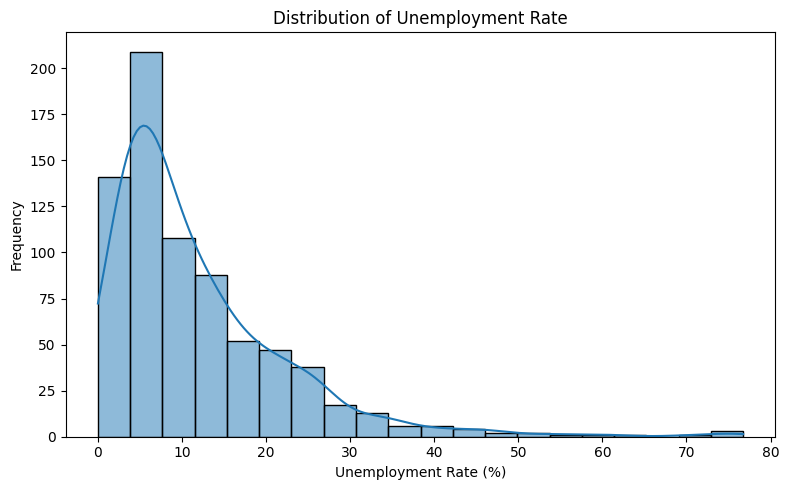

In [6]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df['Estimated Unemployment Rate (%)'],
    bins=20,
    kde=True
)

plt.title("Distribution of Unemployment Rate")
plt.xlabel("Unemployment Rate (%)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("unemployment_distribution.png", dpi=300)
plt.show()

Step 6 — Monthly unemployment trend

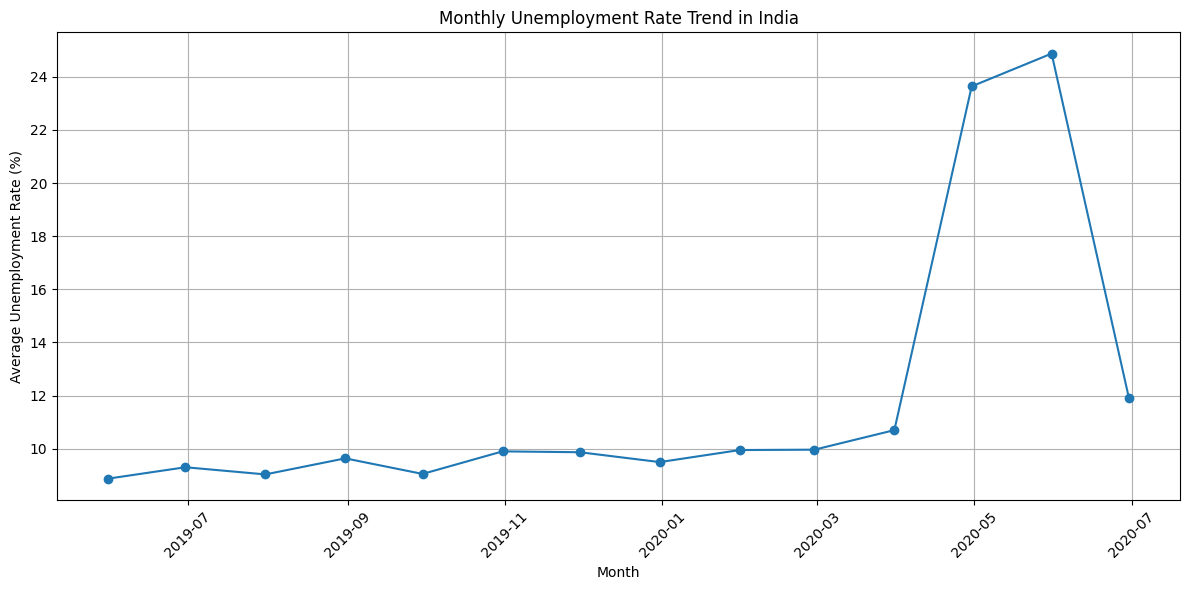

Monthly Average Unemployment Rate:


,Estimated Unemployment Rate (%)
Date,
2019-05-31,8.87
2019-06-30,9.30
2019-07-31,9.03
2019-08-31,9.64
2019-09-30,9.05
2019-10-31,9.90
2019-11-30,9.87
2019-12-31,9.50
2020-01-31,9.95


In [7]:
# Calculate average unemployment rate for each month
monthly_unemployment = (
    df.groupby('Date')['Estimated Unemployment Rate (%)']
    .mean()
    .sort_index()
)

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_unemployment.index,
    monthly_unemployment.values,
    marker='o'
)

plt.title("Monthly Unemployment Rate Trend in India")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.savefig("monthly_unemployment_trend.png", dpi=300)
plt.show()

print("Monthly Average Unemployment Rate:")
display(monthly_unemployment.round(2))

Step 7 — Unemployment rate by region

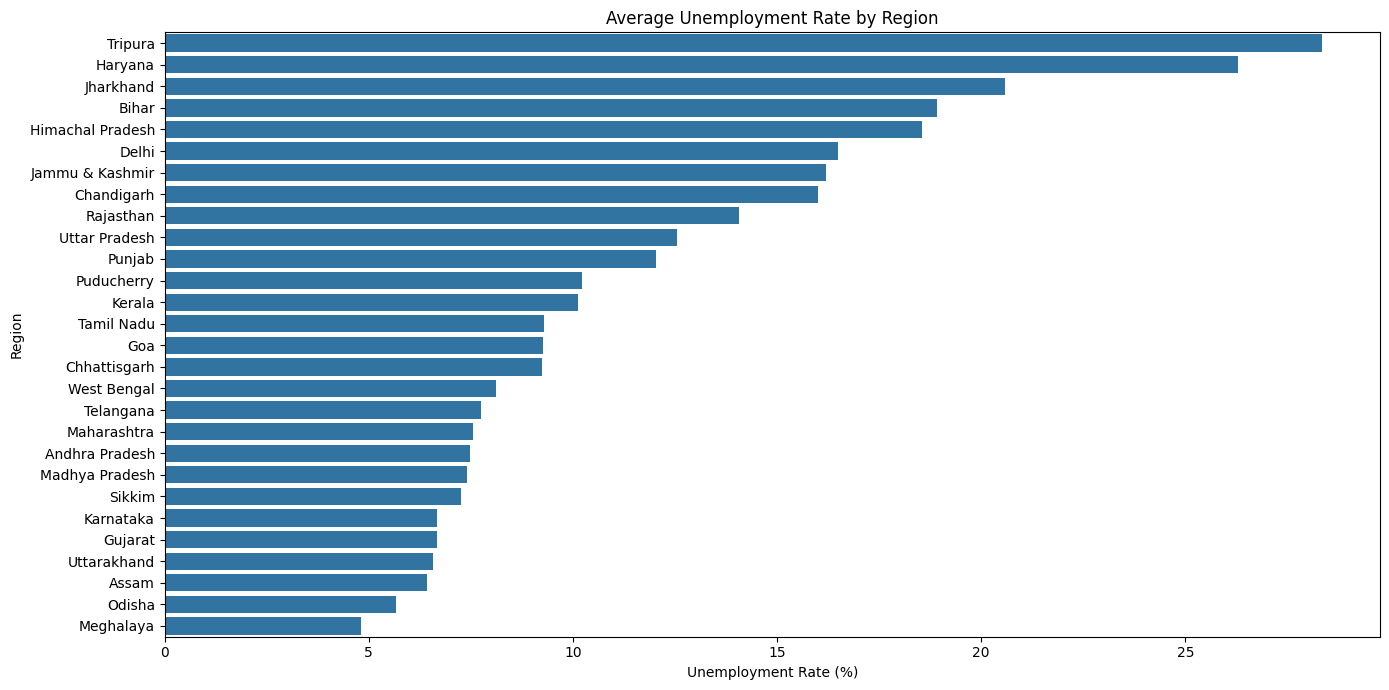

Region-wise Average Unemployment:


,Estimated Unemployment Rate (%)
Region,
Tripura,28.35
Haryana,26.28
Jharkhand,20.58
Bihar,18.92
Himachal Pradesh,18.54
Delhi,16.50
Jammu & Kashmir,16.19
Chandigarh,15.99
Rajasthan,14.06


In [8]:
# Average unemployment rate by region
region_unemployment = (
    df.groupby('Region')['Estimated Unemployment Rate (%)']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(14, 7))

sns.barplot(
    x=region_unemployment.values,
    y=region_unemployment.index
)

plt.title("Average Unemployment Rate by Region")
plt.xlabel("Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.savefig("region_unemployment.png", dpi=300)
plt.show()

print("Region-wise Average Unemployment:")
display(region_unemployment.round(2))

Step 8 — Rural vs Urban unemployment

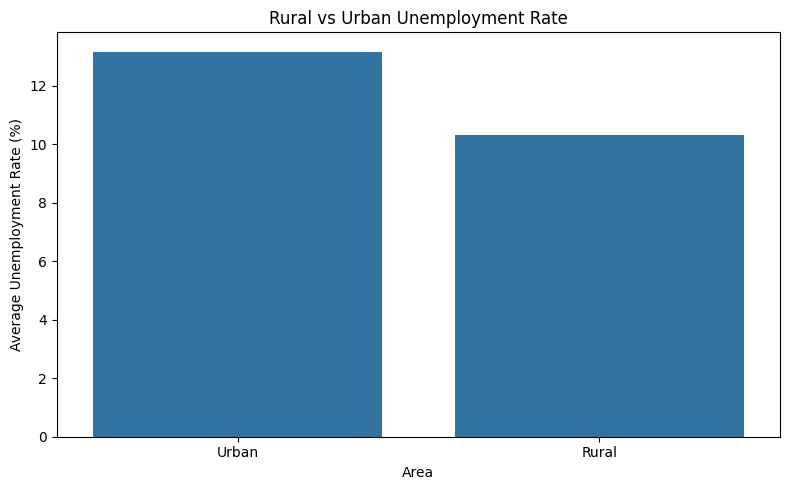

Area-wise Average Unemployment:


,Estimated Unemployment Rate (%)
Area,
Urban,13.17
Rural,10.32


In [9]:
# Calculate average unemployment by area
area_unemployment = (
    df.groupby('Area')['Estimated Unemployment Rate (%)']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=area_unemployment.index,
    y=area_unemployment.values
)

plt.title("Rural vs Urban Unemployment Rate")
plt.xlabel("Area")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.savefig("rural_urban_unemployment.png", dpi=300)
plt.show()

print("Area-wise Average Unemployment:")
display(area_unemployment.round(2))

Step 9 — COVID-19 impact analysis

In [10]:
# Define COVID-19 cutoff date
covid_date = pd.Timestamp('2020-03-25')

# Divide data into two periods
before_covid = df[df['Date'] < covid_date]
during_covid = df[df['Date'] >= covid_date]

# Calculate average unemployment rates
before_rate = before_covid['Estimated Unemployment Rate (%)'].mean()
during_rate = during_covid['Estimated Unemployment Rate (%)'].mean()

print("Before COVID-19 Average:", round(before_rate, 2), "%")
print("During COVID-19 Average:", round(during_rate, 2), "%")

# Calculate percentage increase
percentage_increase = (
    (during_rate - before_rate) / before_rate
) * 100

print("Percentage Increase:", round(percentage_increase, 2), "%")

Before COVID-19 Average: 9.51 %
During COVID-19 Average: 17.77 %
Percentage Increase: 86.91 %


Step 10 — Visualize COVID-19 impact

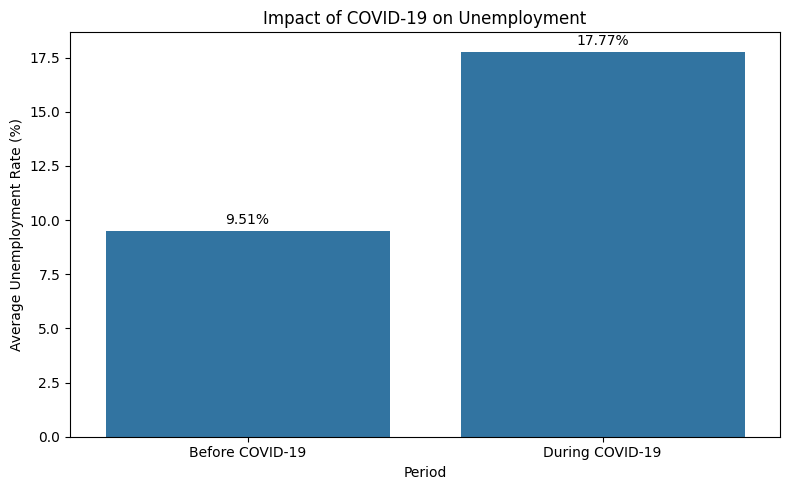

In [11]:
covid_comparison = pd.DataFrame({
    'Period': ['Before COVID-19', 'During COVID-19'],
    'Unemployment Rate': [before_rate, during_rate]
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=covid_comparison,
    x='Period',
    y='Unemployment Rate'
)

plt.title("Impact of COVID-19 on Unemployment")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")

for i, value in enumerate(covid_comparison['Unemployment Rate']):
    plt.text(i, value + 0.3, f"{value:.2f}%", ha='center')

plt.tight_layout()
plt.savefig("covid_impact_comparison.png", dpi=300)
plt.show()

Step 11 — Monthly unemployment during COVID-19

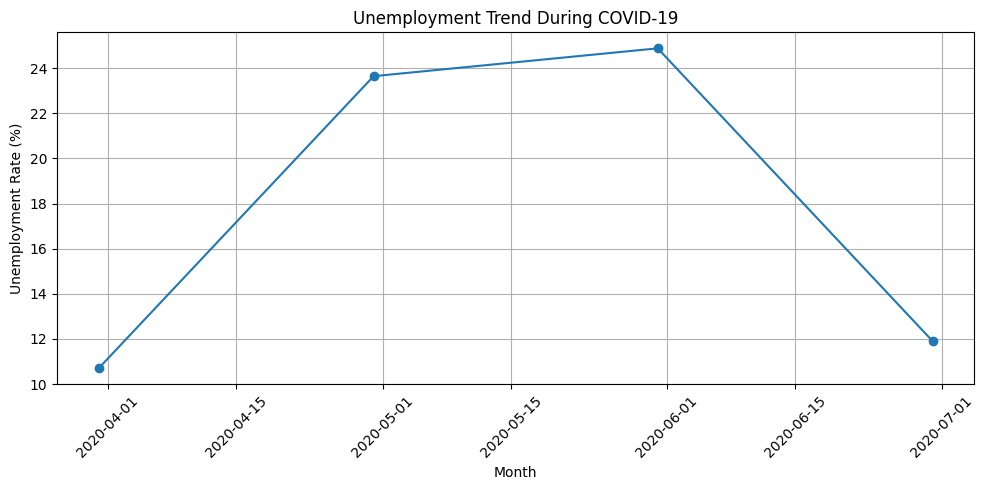

,Estimated Unemployment Rate (%)
Date,
2020-03-31,10.70
2020-04-30,23.64
2020-05-31,24.88
2020-06-30,11.90


In [12]:
# Filter COVID-period data
covid_monthly = (
    df[df['Date'] >= covid_date]
    .groupby('Date')['Estimated Unemployment Rate (%)']
    .mean()
    .sort_index()
)

plt.figure(figsize=(10, 5))

plt.plot(
    covid_monthly.index,
    covid_monthly.values,
    marker='o'
)

plt.title("Unemployment Trend During COVID-19")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.savefig("covid_monthly_trend.png", dpi=300)
plt.show()

display(covid_monthly.round(2))

Step 12 — Estimated employment analysis

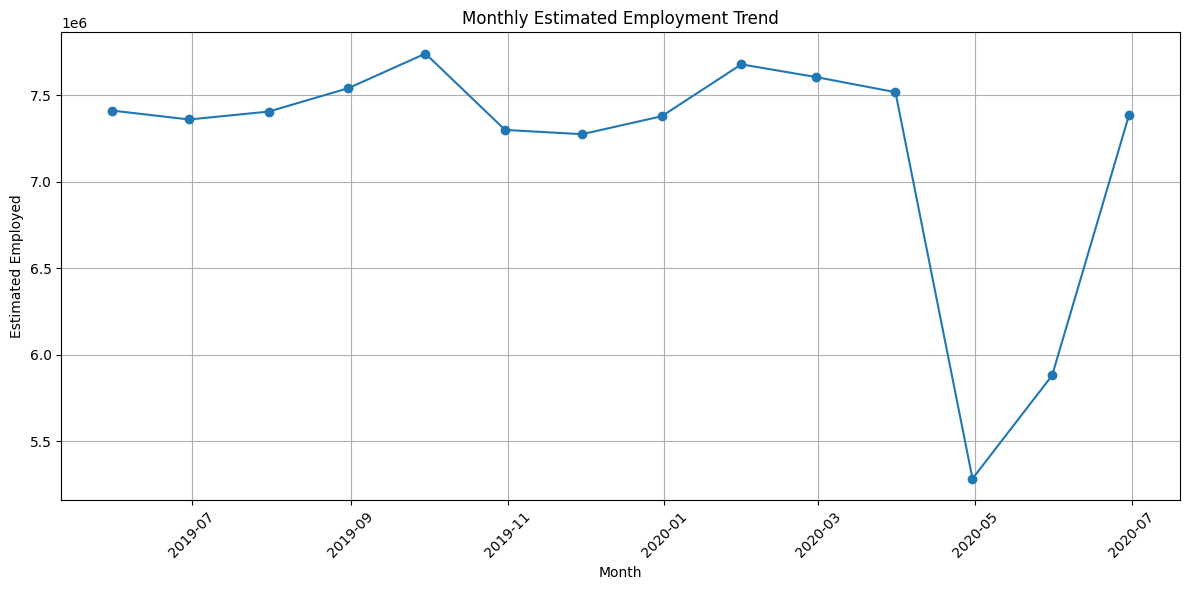

In [13]:
monthly_employment = (
    df.groupby('Date')['Estimated Employed']
    .mean()
    .sort_index()
)

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_employment.index,
    monthly_employment.values,
    marker='o'
)

plt.title("Monthly Estimated Employment Trend")
plt.xlabel("Month")
plt.ylabel("Estimated Employed")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.savefig("employment_trend.png", dpi=300)
plt.show()

Step 13 — Labour participation rate analysis

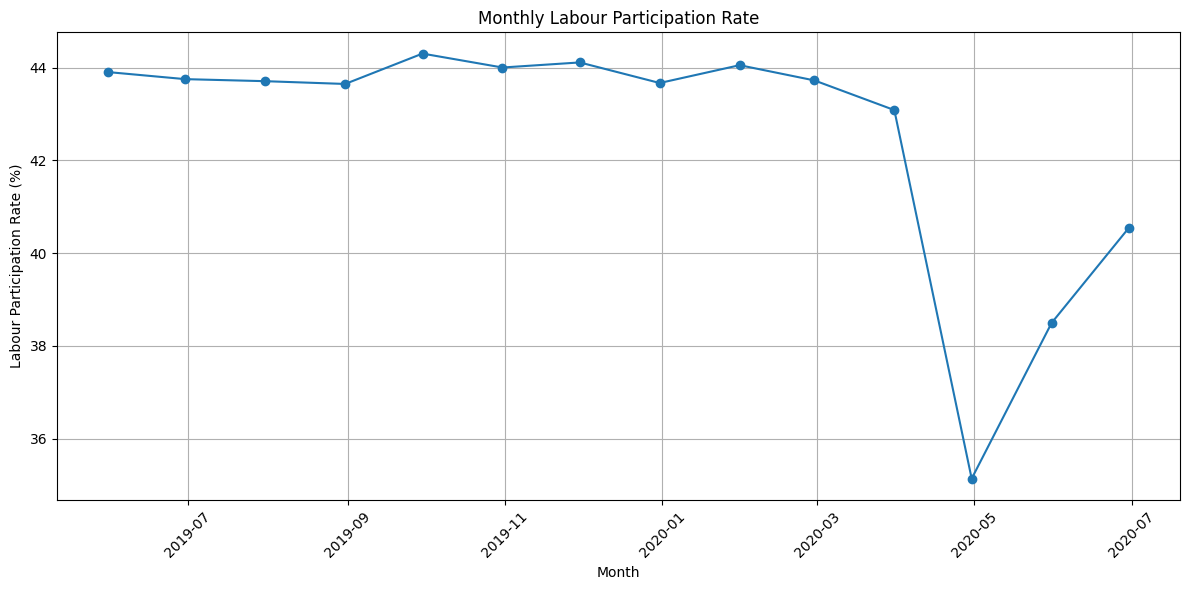

In [14]:
monthly_participation = (
    df.groupby('Date')['Estimated Labour Participation Rate (%)']
    .mean()
    .sort_index()
)

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_participation.index,
    monthly_participation.values,
    marker='o'
)

plt.title("Monthly Labour Participation Rate")
plt.xlabel("Month")
plt.ylabel("Labour Participation Rate (%)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.savefig("labour_participation_trend.png", dpi=300)
plt.show()

Step 14 — Correlation heatmap

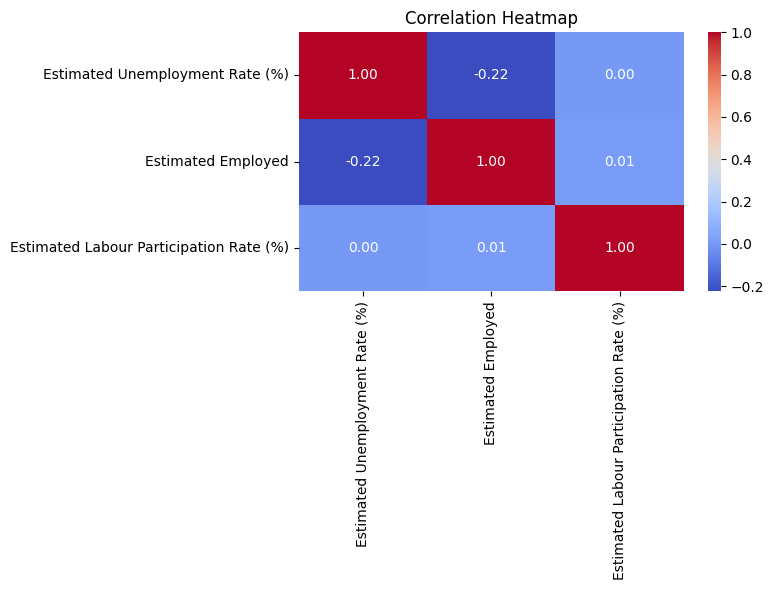

In [15]:
# Select numeric columns
numeric_df = df.select_dtypes(include=np.number)

# Calculate correlation
correlation = numeric_df.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=300)
plt.show()

Step 15 — Top 10 regions with highest unemployment

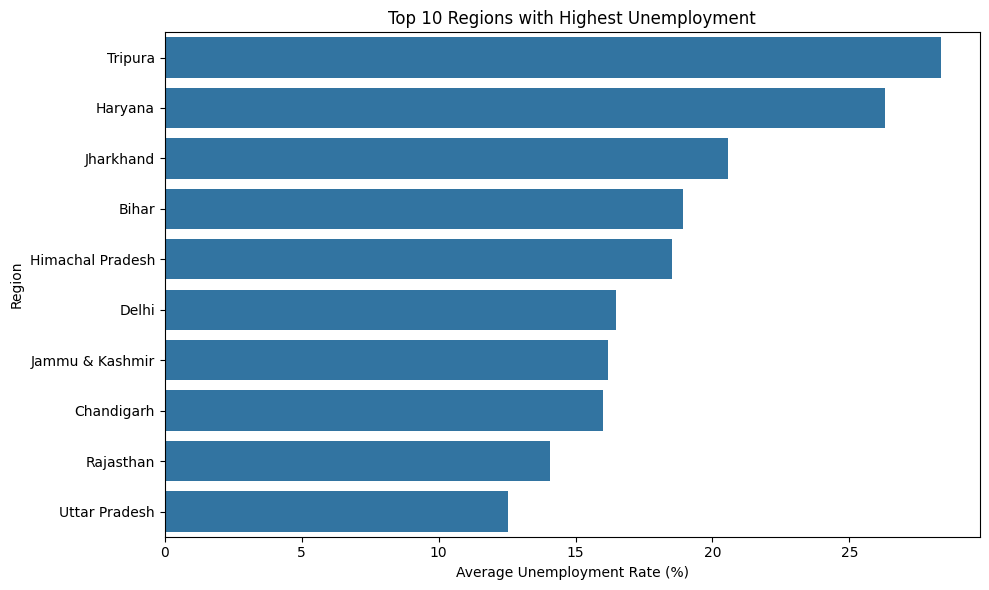

,Estimated Unemployment Rate (%)
Region,
Tripura,28.35
Haryana,26.28
Jharkhand,20.58
Bihar,18.92
Himachal Pradesh,18.54
Delhi,16.50
Jammu & Kashmir,16.19
Chandigarh,15.99
Rajasthan,14.06


In [16]:
top_10_regions = region_unemployment.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_10_regions.values,
    y=top_10_regions.index
)

plt.title("Top 10 Regions with Highest Unemployment")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.savefig("top_10_regions.png", dpi=300)
plt.show()

display(top_10_regions.round(2))

Step 16 — Identify the lowest unemployment regions

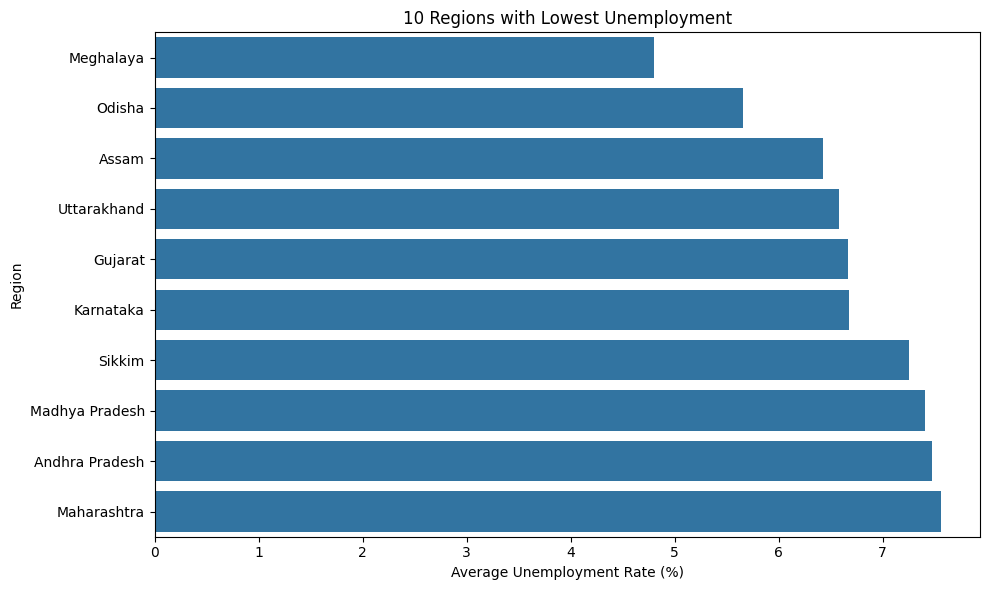

,Estimated Unemployment Rate (%)
Region,
Meghalaya,4.80
Odisha,5.66
Assam,6.43
Uttarakhand,6.58
Gujarat,6.66
Karnataka,6.68
Sikkim,7.25
Madhya Pradesh,7.41
Andhra Pradesh,7.48


In [17]:
bottom_10_regions = region_unemployment.tail(10).sort_values()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=bottom_10_regions.values,
    y=bottom_10_regions.index
)

plt.title("10 Regions with Lowest Unemployment")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.savefig("bottom_10_regions.png", dpi=300)
plt.show()

display(bottom_10_regions.round(2))

Step 17 — Final findings and summary

In [18]:
print("=" * 50)
print("        UNEMPLOYMENT ANALYSIS SUMMARY")
print("=" * 50)

print("Total Records:", len(df))
print("Total Regions:", df['Region'].nunique())

print(
    "Overall Average Unemployment Rate:",
    round(df['Estimated Unemployment Rate (%)'].mean(), 2), "%"
)

print(
    "Before COVID Average:",
    round(before_rate, 2), "%"
)

print(
    "During COVID Average:",
    round(during_rate, 2), "%"
)

print(
    "Percentage Increase:",
    round(percentage_increase, 2), "%"
)

print(
    "Highest Unemployment Region:",
    region_unemployment.idxmax(),
    round(region_unemployment.max(), 2), "%"
)

print(
    "Lowest Unemployment Region:",
    region_unemployment.idxmin(),
    round(region_unemployment.min(), 2), "%"
)

print(
    "Rural Average:",
    round(df[df['Area'] == 'Rural']
          ['Estimated Unemployment Rate (%)'].mean(), 2), "%"
)

print(
    "Urban Average:",
    round(df[df['Area'] == 'Urban']
          ['Estimated Unemployment Rate (%)'].mean(), 2), "%"
)

print("=" * 50)

        UNEMPLOYMENT ANALYSIS SUMMARY
Total Records: 740
Total Regions: 28
Overall Average Unemployment Rate: 11.79 %
Before COVID Average: 9.51 %
During COVID Average: 17.77 %
Percentage Increase: 86.91 %
Highest Unemployment Region: Tripura 28.35 %
Lowest Unemployment Region: Meghalaya 4.8 %
Rural Average: 10.32 %
Urban Average: 13.17 %


Step 18 — Export cleaned dataset

In [19]:
# Save cleaned dataset
df.to_csv("Unemployment_Cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


Step 19 —  all graphs

In [20]:
import os
import zipfile

# List of graphs created by the project
graph_files = [
    "unemployment_distribution.png",
    "monthly_unemployment_trend.png",
    "region_unemployment.png",
    "rural_urban_unemployment.png",
    "covid_impact_comparison.png",
    "covid_monthly_trend.png",
    "employment_trend.png",
    "labour_participation_trend.png",
    "correlation_heatmap.png",
    "top_10_regions.png",
    "bottom_10_regions.png"
]

# Create ZIP file
with zipfile.ZipFile("Unemployment_Project_Results.zip", "w") as zipf:

    for file in graph_files:
        if os.path.exists(file):
            zipf.write(file)

    if os.path.exists("Unemployment_Cleaned.csv"):
        zipf.write("Unemployment_Cleaned.csv")

print("Project results ZIP created successfully!")

Project results ZIP created successfully!


Step 20 — Download the ZIP to your computer

In [21]:
from google.colab import files

files.download("Unemployment_Project_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>